In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
checkpoint = "dccuchile/bert-base-spanish-wwm-uncased"
HF_TOKEN = "TOKEN_HUGGING"

In [ ]:
best_hiperparameters = {
    'learning_rate': 2.1811346114456894e-05,
    'weight_decay': 0.038489172815407285,
    'warmup_ratio': 0.046701944300902645,
    'per_device_train_batch_size': 32,
    'num_train_epochs': 11
}

# Clasificación en Binario del Dataset

In [ ]:
from datasets import load_dataset

# Carga todo el dataset
dataset = load_dataset("textdetox/multilingual_toxicity_dataset", split="es", token=HF_TOKEN)
df = dataset.to_pandas()
df = df.rename(columns={'toxic': 'labels'})

## Setup

In [ ]:
!pip install textacy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 210.7/210.7 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 117.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 321.6/321.6 kB 31.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 360.5/360.5 kB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 106.9 MB/s eta 0:00:00


In [ ]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.6 MB/s eta 0:00:00


In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 22.1 MB/s eta 0:00:00


## Preprocesamiento
*	Eliminación de URLs.
*	Sustitución de menciones por el token @USER.
*	Normalización de espacios.
*	Eliminación de caracteres de control.

In [ ]:
import re
import pandas as pd
import textacy
import textacy.preprocessing as tprep

def normalize(text):
  text = tprep.replace.urls(text)
  text = tprep.replace.emojis(text)
  text = tprep.replace.user_handles(text)
  text = tprep.replace.hashtags(text)
  text = tprep.replace.numbers(text)
  text = tprep.replace.currency_symbols(text)
  text = tprep.replace.emails(text)

  text = tprep.normalize.whitespace(text)

  return text

df["text"] = df["text"].astype(str).apply(normalize)

df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

### Distribucion Dataset

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["labels"],
    random_state=42
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["labels"],
    random_state=42
)

from datasets import Dataset

train_dataset_raw = Dataset.from_pandas(train_df.reset_index(drop=True))
valid_dataset_raw = Dataset.from_pandas(valid_df.reset_index(drop=True))
test_dataset_raw = Dataset.from_pandas(test_df.reset_index(drop=True))

print(f"Training set size: {len(train_dataset_raw)}")
print(f"Validation set size: {len(valid_dataset_raw)}")
print(f"Test set size: {len(test_dataset_raw)}")

Training set size: 4000
Validation set size: 500
Test set size: 500


### Tokenizacion

In [ ]:
from transformers import AutoTokenizer
from datasets import Dataset, load_from_disk

tokenizer = AutoTokenizer.from_pretrained(checkpoint, token=HF_TOKEN)

def tokenize_function(data):
  return tokenizer(data["text"], truncation=True,max_length=128)

train_dataset_raw = Dataset.from_pandas(train_df.reset_index(drop=True))
valid_dataset_raw = Dataset.from_pandas(valid_df.reset_index(drop=True))
test_dataset_raw = Dataset.from_pandas(test_df.reset_index(drop=True))

valid_dataset = load_from_disk("/content/drive/MyDrive/Sesgo/model_beto_data/valid_dataset")
train_dataset = load_from_disk("/content/drive/MyDrive/Sesgo/model_beto_data/train_dataset")
test_dataset = load_from_disk("/content/drive/MyDrive/Sesgo/model_beto_data/test_dataset")

# train_dataset = train_dataset_raw.map(
#     tokenize_function,
#     batched=True
# )

# valid_dataset = valid_dataset_raw.map(
#     tokenize_function,
#     batched=True
# )

# test_dataset = test_dataset_raw.map(
#     tokenize_function,
#     batched=True
# )

In [ ]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

## Fine Tuning

### Hiperparámetros

In [ ]:
import numpy as np
from evaluate import load

accuracy = load("accuracy")
precision = load("precision")
recall = load("recall")
f1 = load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy.compute(
            predictions=predictions,
            references=labels
        )["accuracy"],

        "precision": precision.compute(
            predictions=predictions,
            references=labels
        )["precision"],

        "recall": recall.compute(
            predictions=predictions,
            references=labels
        )["recall"],

        "f1": f1.compute(
            predictions=predictions,
            references=labels
        )["f1"],

        "macro_f1": f1.compute(
            predictions=predictions,
            references=labels,
            average="macro"
        )["f1"]
    }

def hp_space(trial):
  return {
    "learning_rate": trial.suggest_float(
      "learning_rate",
      1e-5,
      5e-5,
      log=True
    ),
    "weight_decay": trial.suggest_float(
      "weight_decay",
      0.0,
      0.1
    ),
    "warmup_steps": trial.suggest_float(
      "warmup_steps",
      0.0,
      0.2
    ),
    "per_device_train_batch_size": trial.suggest_categorical(
      "per_device_train_batch_size",
      [8, 16, 32]
    ),
    "num_train_epochs": trial.suggest_int(
      "num_train_epochs",
      5,
      12
    )
  }

def compute_objective(metrics):
    return metrics["eval_macro_f1"]

### Configuracion General

In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./results",
    learning_rate=best_hiperparameters["learning_rate"],
    weight_decay=best_hiperparameters["weight_decay"],
    per_device_train_batch_size=best_hiperparameters["per_device_train_batch_size"],
    per_device_eval_batch_size=16,
    num_train_epochs=best_hiperparameters["num_train_epochs"],
    warmup_steps=best_hiperparameters["warmup_ratio"],
    lr_scheduler_type="linear",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    seed=42,
    fp16=True
)

In [ ]:
from transformers import Trainer, EarlyStoppingCallback, AutoModelForSequenceClassification

def model_init():
  return AutoModelForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=2,
    token=HF_TOKEN
  )

trainer = Trainer(
  model_init=model_init,
  args=training_args,
  train_dataset=train_dataset,
  eval_dataset=valid_dataset,
  data_collator=data_collator,
  compute_metrics=compute_metrics,
  callbacks=[
    EarlyStoppingCallback(
      early_stopping_patience=3
    )
  ]
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING

In [ ]:
best_run = trainer.hyperparameter_search(
    backend="optuna",
    hp_space=hp_space,
    compute_objective=compute_objective,
    n_trials=20
)

[I 2026-07-15 11:11:59,262] A new study created in memory with name: no-name-43992f81-9c88-4b82-9dd6-0a15098453ac


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1
1,0.411502,0.235167,0.906000,0.924686,0.884000,0.903885,0.905954
2,0.210861,0.276908,0.918000,0.909804,0.928000,0.918812,0.917992
3,0.066427,0.499145,0.902000,0.938865,0.860000,0.897704,0.901827
4,0.020168,0.510637,0.910000,0.898833,0.924000,0.911243,0.909982
5,0.006249,0.542093,0.912000,0.929167,0.892000,0.910204,0.911965


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (147 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1
1,0.448099,0.242866,0.910000,0.925311,0.892000,0.908350,0.909971


[I 2026-07-15 12:29:11,351] Trial 19 pruned. 


In [ ]:
print(best_run.hyperparameters)

{'learning_rate': 2.1811346114456894e-05, 'weight_decay': 0.038489172815407285, 'warmup_ratio': 0.046701944300902645, 'per_device_train_batch_size': 32, 'num_train_epochs': 11}


In [ ]:
from transformers import Trainer, EarlyStoppingCallback, AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=2,
    token=HF_TOKEN
)

trainer = Trainer(
  model=model,
  args=training_args,
  train_dataset=train_dataset,
  eval_dataset=valid_dataset,
  data_collator=data_collator,
  compute_metrics=compute_metrics,
  callbacks=[
    EarlyStoppingCallback(
      early_stopping_patience=3
    )
  ]
)

trainer.train()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1
1,0.440836,0.230303,0.902000,0.913580,0.888000,0.900609,0.901981
2,0.208527,0.233214,0.908000,0.886364,0.936000,0.910506,0.907928
3,0.098471,0.276283,0.904000,0.900794,0.908000,0.904382,0.903998
4,0.037059,0.392032,0.924000,0.949153,0.896000,0.921811,0.923940
5,0.012425,0.509067,0.914000,0.905882,0.924000,0.914851,0.913991
6,0.004517,0.593444,0.910000,0.921811,0.896000,0.908722,0.909982
7,0.003212,0.564811,0.918000,0.919679,0.916000,0.917836,0.918000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=875, training_loss=0.11500670184407916, metrics={'train_runtime': 223.5163, 'train_samples_per_second': 196.854, 'train_steps_per_second': 6.152, 'total_flos': 1561251669183360.0, 'train_loss': 0.11500670184407916, 'epoch': 7.0})

In [ ]:
trainer.save_model("/content/drive/MyDrive/Sesgo/model_beto")

tokenizer.save_pretrained("/content/drive/MyDrive/Sesgo/model_beto")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/Sesgo/model_beto/tokenizer_config.json',
 '/content/drive/MyDrive/Sesgo/model_beto/tokenizer.json')

### Evaluacion del modelo

In [ ]:
results = trainer.evaluate(test_dataset)

print(results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Macro F1
0.000437,0.732239,11,0.910000,0.889734,0.936000,0.912281,0.909939


{'eval_loss': 0.7322390079498291, 'eval_accuracy': 0.91, 'eval_precision': 0.8897338403041825, 'eval_recall': 0.936, 'eval_f1': 0.9122807017543859, 'eval_macro_f1': 0.9099391188443388}


Matriz de Confusion

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

predictions = trainer.predict(test_dataset)

preds = np.argmax(predictions.predictions, axis=1)

labels = predictions.label_ids

cm = confusion_matrix(labels, preds)


disp = ConfusionMatrixDisplay(cm)

disp.plot(cmap="Blues")

plt.show()

[[221  29]
 [ 16 234]]


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        labels,
        preds,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9325    0.8840    0.9076       250
           1     0.8897    0.9360    0.9123       250

    accuracy                         0.9100       500
   macro avg     0.9111    0.9100    0.9099       500
weighted avg     0.9111    0.9100    0.9099       500



Funcion de Perdida

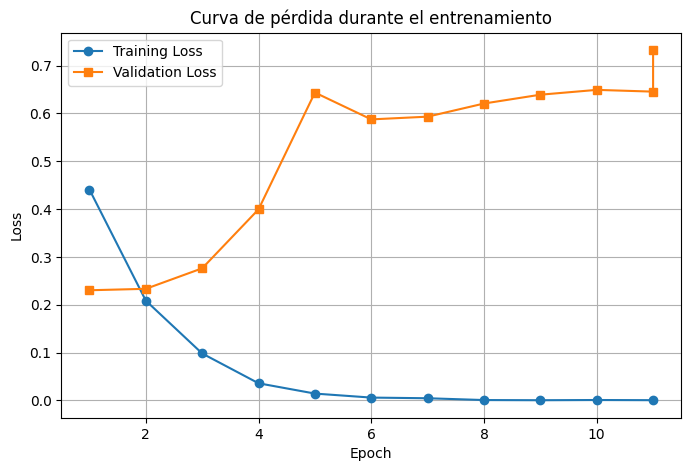

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Historial del entrenamiento
history = pd.DataFrame(trainer.state.log_history)

# Extraer pérdidas
train_loss = history[history["loss"].notna()][["epoch", "loss"]]
eval_loss = history[history["eval_loss"].notna()][["epoch", "eval_loss"]]

# Gráfica
plt.figure(figsize=(8,5))

plt.plot(
    train_loss["epoch"],
    train_loss["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    eval_loss["epoch"],
    eval_loss["eval_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Curva de pérdida durante el entrenamiento")
plt.grid(True)
plt.legend()

plt.show()

# Modelo 2 con Vocabulario Bilma

## Setup

In [ ]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.5 MB/s eta 0:00:00


In [ ]:
!pip install textacy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 210.7/210.7 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 321.6/321.6 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 360.5/360.5 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 83.0 MB/s eta 0:00:00


## Carga Dataset

In [ ]:
from datasets import load_dataset

# Carga todo el dataset
dataset = load_dataset("textdetox/multilingual_toxicity_dataset", split="es")

df = dataset.to_pandas()
df = df.rename(columns={'toxic': 'labels'})

README.md:   0%|          | 0.00/8.91k [00:00<?, ?B/s]

data/en-00000-of-00001.parquet:   0%|          | 0.00/267k [00:00<?, ?B/s]

data/ru-00000-of-00001.parquet:   0%|          | 0.00/388k [00:00<?, ?B/s]

data/uk-00000-of-00001.parquet:   0%|          | 0.00/360k [00:00<?, ?B/s]

data/de-00000-of-00001.parquet:   0%|          | 0.00/614k [00:00<?, ?B/s]

data/es-00000-of-00001.parquet:   0%|          | 0.00/641k [00:00<?, ?B/s]

... (21 outputs left out)

Generating he split:   0%|          | 0/2011 [00:00<?, ? examples/s]

Generating hin split:   0%|          | 0/4363 [00:00<?, ? examples/s]

Generating tt split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating ja split:   0%|          | 0/5000 [00:00<?, ? examples/s]

## Preprocesamiento

In [ ]:
import re
import pandas as pd
import textacy
import textacy.preprocessing as tprep

def normalize(text):
  text = tprep.replace.urls(text)
  text = tprep.replace.emojis(text)
  text = tprep.replace.user_handles(text)
  text = tprep.replace.hashtags(text)
  text = tprep.replace.numbers(text)
  text = tprep.replace.currency_symbols(text)
  text = tprep.replace.emails(text)

  text = tprep.normalize.whitespace(text)

  return text

df["text"] = df["text"].astype(str).apply(normalize)

df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

### Distribucion Dataset

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["labels"],
    random_state=42
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["labels"],
    random_state=42
)

from datasets import Dataset

train_dataset_raw = Dataset.from_pandas(train_df.reset_index(drop=True))
valid_dataset_raw = Dataset.from_pandas(valid_df.reset_index(drop=True))
test_dataset_raw = Dataset.from_pandas(test_df.reset_index(drop=True))

print(f"Training set size: {len(train_dataset_raw)}")
print(f"Validation set size: {len(valid_dataset_raw)}")
print(f"Test set size: {len(test_dataset_raw)}")

In [ ]:
import os
import pandas as pd
from tqdm import tqdm

PATH_CSV = "/content/drive/MyDrive/Sesgo/bilma"

country_files = [
    f for f in os.listdir(PATH_CSV)
    if f.endswith(".tsv") and f != "ALL.tsv"
]

print(f"Total de países encontrados: {len(country_files)}")
print(country_files[:10])

Total de países encontrados: 7
['MX.tsv', 'CO.tsv', 'AR.tsv', 'US.tsv', 'PE.tsv', 'ES.tsv', 'CL.tsv']


## Diccionario

In [ ]:
import os
import re
import numpy as np
import pandas as pd
from tqdm import tqdm

dialect_dict = {}

for file in tqdm(country_files):

    country = file.replace(".tsv", "")

    df = pd.read_csv(
        os.path.join(PATH_CSV, file),
        sep="\t"
    )

    # ============================
    # Columnas necesarias
    # ============================
    df = df[["token", "occs", "ndocs", "weight"]]

    # ============================
    # Eliminar nulos
    # ============================
    df = df.dropna(subset=["token", "occs", "ndocs", "weight"])

    # ============================
    # Normalizar tokens
    # ============================
    df["token"] = (
        df["token"]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    # ============================
    # Eliminar duplicados
    # ============================
    df = df.drop_duplicates(subset="token")

    # ============================
    # Solo palabras
    # ============================
    df = df[
        df["token"].str.match(
            r"^[a-záéíóúüñ]+$",
            na=False
        )
    ]

    # ============================
    # Longitud
    # ============================
    df = df[
        (df["token"].str.len() >= 2) &
        (df["token"].str.len() <= 30)
    ]

    # ============================
    # Frecuencia mínima
    # ============================
    df = df[
        df["occs"] >= 5
    ]

    # ============================
    # Pesos válidos
    # ============================
    df = df[
        df["weight"] > 0
    ]

    # ============================
    # Score dialectal
    # ============================
    df["dialect_score"] = (
        np.log1p(df["occs"]) *
        df["weight"]
    )

    # ============================
    # Construcción del diccionario
    # ============================
    for row in df.itertuples(index=False):

        token = row.token

        if token not in dialect_dict:
            dialect_dict[token] = {}

        dialect_dict[token][country] = {

            "score": float(row.dialect_score),

            "occs": int(row.occs),

            "ndocs": int(row.ndocs),

            "weight": float(row.weight)

        }

print(f"Palabras del diccionario: {len(dialect_dict):,}")

100%|██████████| 7/7 [00:34<00:00,  4.92s/it]

Palabras del diccionario: 1,117,825


## Tokenizacion

In [ ]:
from transformers import AutoTokenizer
import re

tokenizer = AutoTokenizer.from_pretrained(checkpoint)

def lexical_tokenizer(text):
    return re.findall(
        r"[a-záéíóúüñ]+",
        text.lower()
    )

def enrich_text(text):
    tokens = lexical_tokenizer(text)

    tags = []

    for token in tokens:

        if token not in dialect_dict:
            continue

        countries = dialect_dict[token]

        # Elegir el país donde el token tiene mayor score
        best_country = max(
            countries.items(),
            key=lambda x: x[1]["score"]
        )[0]

        tags.append(f"[{best_country}]")

    # eliminar repetidos
    tags = list(dict.fromkeys(tags))

    if len(tags):

        text = " ".join(tags) + " " + text

    return text

def tokenize_function(batch):
    enriched_texts = [
        enrich_text(text)
        for text in batch["text"]
    ]

    return tokenizer(
        enriched_texts,
        truncation=True,
        max_length=128
    )

special_tokens = [
    "[MX]",
    "[CO]",
    "[AR]",
    "[US]",
    "[PE]",
    "[ES]",
    "[CL]"
]

tokenizer.add_special_tokens(
    {
        "additional_special_tokens": special_tokens
    }
)

config.json:   0%|          | 0.00/650 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/310 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/486k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

7

In [ ]:
from datasets import Dataset, load_from_disk

train_dataset_raw = Dataset.from_pandas(train_df.reset_index(drop=True))
valid_dataset_raw = Dataset.from_pandas(valid_df.reset_index(drop=True))
test_dataset_raw = Dataset.from_pandas(test_df.reset_index(drop=True))

train_dataset = load_from_disk("/content/drive/MyDrive/Sesgo/model_dialectlex_data/train_dataset")
valid_dataset = load_from_disk("/content/drive/MyDrive/Sesgo/model_dialectlex_data/valid_dataset")
test_dataset = load_from_disk("/content/drive/MyDrive/Sesgo/model_dialectlex_data/test_dataset")

# train_dataset = train_dataset_raw.map(
#     tokenize_function,
#     batched=True
# )

# valid_dataset = valid_dataset_raw.map(
#     tokenize_function,
#     batched=True
# )

# test_dataset = test_dataset_raw.map(
#     tokenize_function,
#     batched=True
# )


Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [ ]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

Ahora empezamos con el fine tuning del modelo
## Fine Tuning

### Hiperparámetros

In [ ]:
import numpy as np
from evaluate import load

accuracy = load("accuracy")
precision = load("precision")
recall = load("recall")
f1 = load("f1")


def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy.compute(
            predictions=predictions,
            references=labels
        )["accuracy"],

        "precision": precision.compute(
            predictions=predictions,
            references=labels
        )["precision"],

        "recall": recall.compute(
            predictions=predictions,
            references=labels
        )["recall"],

        "f1": f1.compute(
            predictions=predictions,
            references=labels
        )["f1"],

        "macro_f1": f1.compute(
            predictions=predictions,
            references=labels,
            average="macro"
        )["f1"]
    }

def compute_objective(metrics):
    return metrics["eval_macro_f1"]

### Configuracion General

In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./results",

    # Optimización
    learning_rate=best_hiperparameters['learning_rate'],
    weight_decay=best_hiperparameters['weight_decay'],

    # Batch
    per_device_train_batch_size=best_hiperparameters['per_device_train_batch_size'],
    per_device_eval_batch_size=16,

    # Entrenamiento
    num_train_epochs=best_hiperparameters['num_train_epochs'],

    # Warmup
    warmup_steps=best_hiperparameters['warmup_ratio'],

    # Scheduler
    lr_scheduler_type="linear",

    # Evaluación
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",

    # Mejor modelo
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,

    # Almacenamiento
    save_total_limit=2,

    # Reproducibilidad
    seed=42,

    # Rendimiento
    fp16=True
)

In [ ]:
from transformers import Trainer, EarlyStoppingCallback, AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=2,
    token=HF_TOKEN
)

model.resize_token_embeddings(len(tokenizer))

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=3
        )
    ]
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1
1,0.428634,0.242275,0.896000,0.919492,0.868000,0.893004,0.895918
2,0.195991,0.221703,0.910000,0.936170,0.880000,0.907216,0.909919
3,0.092569,0.265382,0.918000,0.960352,0.872000,0.914046,0.917826
4,0.035678,0.371346,0.912000,0.915323,0.908000,0.911647,0.911999
5,0.016298,0.457963,0.914000,0.948052,0.876000,0.910603,0.913876
6,0.011344,0.502146,0.908000,0.947368,0.864000,0.903766,0.907822


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=750, training_loss=0.1300857400894165, metrics={'train_runtime': 254.7082, 'train_samples_per_second': 172.747, 'train_steps_per_second': 5.398, 'total_flos': 1365809488373760.0, 'train_loss': 0.1300857400894165, 'epoch': 6.0})

In [ ]:
trainer.save_model("/content/drive/MyDrive/Sesgo/model_dialectlex")

tokenizer.save_pretrained("/content/drive/MyDrive/Sesgo/model_dialectlex")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/Sesgo/model_dialectlex/tokenizer_config.json',
 '/content/drive/MyDrive/Sesgo/model_dialectlex/tokenizer.json')

### Evaluacion delo modelo

Matriz de Confusion

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

predictions = trainer.predict(test_dataset)

preds = np.argmax(predictions.predictions, axis=1)

labels = predictions.label_ids

cm = confusion_matrix(labels, preds)

disp = ConfusionMatrixDisplay(cm)

disp.plot(cmap="Blues")

plt.show()

[[225  25]
 [ 22 228]]


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        labels,
        preds,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9109    0.9000    0.9054       250
           1     0.9012    0.9120    0.9066       250

    accuracy                         0.9060       500
   macro avg     0.9061    0.9060    0.9060       500
weighted avg     0.9061    0.9060    0.9060       500



Funcion de Perdida

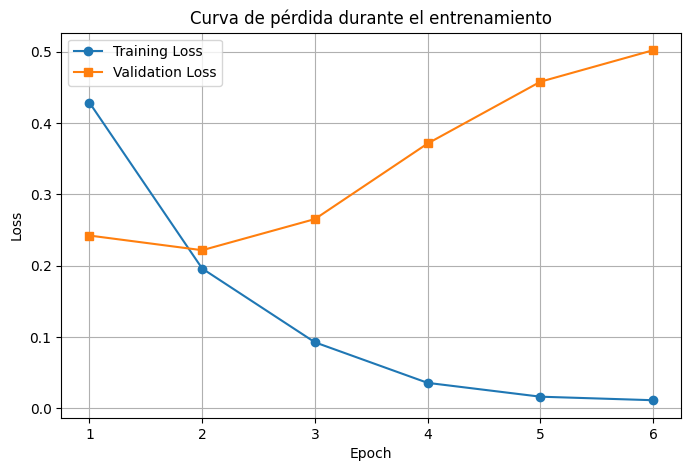

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Historial del entrenamiento
history = pd.DataFrame(trainer.state.log_history)

# Extraer pérdidas
train_loss = history[history["loss"].notna()][["epoch", "loss"]]
eval_loss = history[history["eval_loss"].notna()][["epoch", "eval_loss"]]

# Gráfica
plt.figure(figsize=(8,5))

plt.plot(
    train_loss["epoch"],
    train_loss["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    eval_loss["epoch"],
    eval_loss["eval_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Curva de pérdida durante el entrenamiento")
plt.grid(True)
plt.legend()

plt.show()

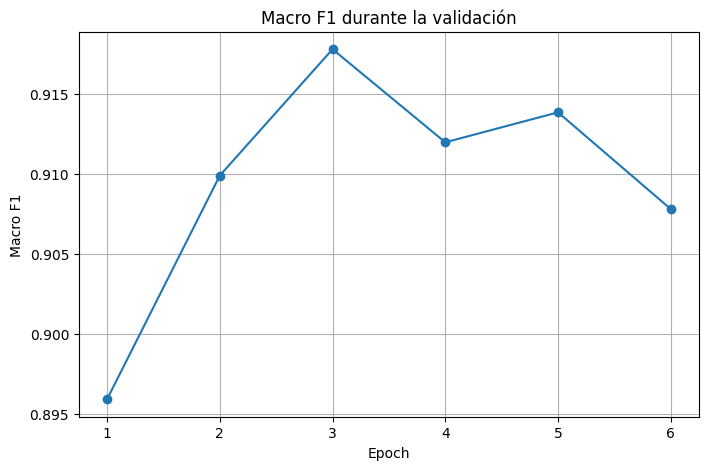

In [ ]:
macro_f1 = history[history["eval_macro_f1"].notna()][["epoch","eval_macro_f1"]]

plt.figure(figsize=(8,5))

plt.plot(
    macro_f1["epoch"],
    macro_f1["eval_macro_f1"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("Macro F1 durante la validación")
plt.grid(True)

plt.show()

Guardando el Modelo

# Comparacion MODELOS

In [ ]:
from transformers import Trainer, AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding, TrainingArguments
from datasets import load_from_disk
import numpy as np
from evaluate import load

accuracy = load("accuracy")
precision = load("precision")
recall = load("recall")
f1 = load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy.compute(
            predictions=predictions,
            references=labels
        )["accuracy"],

        "precision": precision.compute(
            predictions=predictions,
            references=labels
        )["precision"],

        "recall": recall.compute(
            predictions=predictions,
            references=labels
        )["recall"],

        "f1": f1.compute(
            predictions=predictions,
            references=labels
        )["f1"],

        "macro_f1": f1.compute(
            predictions=predictions,
            references=labels,
            average="macro"
        )["f1"]
    }

model1 = AutoModelForSequenceClassification.from_pretrained(
    "/content/drive/MyDrive/Sesgo/model_beto"
)

tokenizer1 = AutoTokenizer.from_pretrained(
    "/content/drive/MyDrive/Sesgo/model_beto"
)

training_args = TrainingArguments(
    output_dir="./results",
    learning_rate=best_hiperparameters['learning_rate'],
    weight_decay=best_hiperparameters['weight_decay'],
    per_device_train_batch_size=best_hiperparameters['per_device_train_batch_size'],
    per_device_eval_batch_size=16,
    num_train_epochs=best_hiperparameters['num_train_epochs'],
    warmup_steps=best_hiperparameters['warmup_ratio'],
    lr_scheduler_type="linear",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    seed=42,
    fp16=True
)

test_dataset = load_from_disk("/content/drive/MyDrive/Sesgo/model_beto_data/test_dataset")

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer1
)

trainer1 = Trainer(
    model=model1,
    args=training_args,
    data_collator=data_collator,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
)

results_model1 = trainer1.evaluate()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Macro F1
No log,0.485056,0,0.912000,0.899225,0.928000,0.913386,0.911977


In [ ]:
from transformers import Trainer, AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding, TrainingArguments
from datasets import load_from_disk
import numpy as np
from evaluate import load

accuracy = load("accuracy")
precision = load("precision")
recall = load("recall")
f1 = load("f1")


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy.compute(
            predictions=predictions,
            references=labels
        )["accuracy"],

        "precision": precision.compute(
            predictions=predictions,
            references=labels
        )["precision"],

        "recall": recall.compute(
            predictions=predictions,
            references=labels
        )["recall"],

        "f1": f1.compute(
            predictions=predictions,
            references=labels
        )["f1"],

        "macro_f1": f1.compute(
            predictions=predictions,
            references=labels,
            average="macro"
        )["f1"]
    }

model2 = AutoModelForSequenceClassification.from_pretrained(
    "/content/drive/MyDrive/Sesgo/model_dialectlex"
)

tokenizer2 = AutoTokenizer.from_pretrained(
    "/content/drive/MyDrive/Sesgo/model_dialectlex"
)

training_args = TrainingArguments(
    output_dir="./results",
    learning_rate=best_hiperparameters['learning_rate'],
    weight_decay=best_hiperparameters['weight_decay'],
    per_device_train_batch_size=best_hiperparameters['per_device_train_batch_size'],
    per_device_eval_batch_size=16,
    num_train_epochs=best_hiperparameters['num_train_epochs'],
    warmup_steps=best_hiperparameters['warmup_ratio'],
    lr_scheduler_type="linear",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    seed=42,
    fp16=True
)

test_dataset = load_from_disk("/content/drive/MyDrive/Sesgo/model_dialectlex_data/test_dataset")

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer2
)

trainer2 = Trainer(
    model=model2,
    args=training_args,
    data_collator=data_collator,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
)

results_model2 = trainer2.evaluate()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Macro F1
No log,0.265385,0,0.922000,0.930612,0.912000,0.921212,0.921992


In [ ]:
import pandas as pd

comparison = pd.DataFrame({

    "Métrica":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Macro F1",
        "Loss"
    ],

    "BETO":[
        results_model1["eval_accuracy"],
        results_model1["eval_precision"],
        results_model1["eval_recall"],
        results_model1["eval_f1"],
        results_model1["eval_macro_f1"],
        results_model1["eval_loss"]
    ],

    "BETO + DialectLex":[
        results_model2["eval_accuracy"],
        results_model2["eval_precision"],
        results_model2["eval_recall"],
        results_model2["eval_f1"],
        results_model2["eval_macro_f1"],
        results_model2["eval_loss"]
    ]

})

comparison

,Métrica,BETO,BETO + DialectLex
0,Accuracy,0.912000,0.922000
1,Precision,0.899225,0.930612
2,Recall,0.928000,0.912000
3,F1,0.913386,0.921212
4,Macro F1,0.911977,0.921992
5,Loss,0.485056,0.265385


In [ ]:
import pandas as pd

data = [

# ==========================
# MEXICO
# ==========================

("MX","Ese wey siempre llega temprano al trabajo.",0),
("MX","Qué chido quedó el proyecto.",0),
("MX","Ese compa me ayudó bastante.",0),
("MX","La neta estuvo muy bien.",0),
("MX","Nos vemos al rato, wey.",0),
("MX","Pinche wey, cállate de una vez.",1),
("MX","Eres un pendejo.",1),
("MX","No sirves para nada, cabrón.",1),
("MX","Vete al carajo.",1),
("MX","Qué idiota eres, wey.",1),

("MX","La comida estuvo deliciosa.",0),
("MX","Ese maestro explica muy bien.",0),
("MX","Qué padre estuvo la reunión.",0),
("MX","Ese chavo juega excelente.",0),
("MX","Todo salió muy bien hoy.",0),
("MX","Pinche inútil.",1),
("MX","Das pena ajena.",1),
("MX","No vales madre.",1),
("MX","Lárgate de aquí.",1),
("MX","Eres un imbécil.",1),

# ==========================
# COLOMBIA
# ==========================

("CO","Ese man trabaja muy duro.",0),
("CO","Qué bacano quedó todo.",0),
("CO","Parcero, muchas gracias.",0),
("CO","Ese pelado estudia bastante.",0),
("CO","Todo salió muy bien.",0),
("CO","Ese man es un idiota.",1),
("CO","No sirves para nada.",1),
("CO","Qué bruto eres.",1),
("CO","Lárguese de aquí.",1),
("CO","Usted da vergüenza.",1),

("CO","Vamos pues, parcero.",0),
("CO","Muy chévere el evento.",0),
("CO","Ese profesor explica excelente.",0),
("CO","Buen trabajo equipo.",0),
("CO","Todo perfecto hoy.",0),
("CO","Usted es un imbécil.",1),
("CO","No haga perder el tiempo.",1),
("CO","Qué estúpido comentario.",1),
("CO","Es un completo inútil.",1),
("CO","Da mucha pena.",1),

# ==========================
# ARGENTINA
# ==========================

("AR","Che, vení un momento.",0),
("AR","Está buenísimo.",0),
("AR","Qué copado quedó.",0),
("AR","Todo salió bárbaro.",0),
("AR","Ese pibe juega bien.",0),
("AR","Sos un boludo.",1),
("AR","Andate de acá.",1),
("AR","Qué idiota sos.",1),
("AR","No servís para nada.",1),
("AR","Sos un inútil.",1),

("AR","Qué linda tarde.",0),
("AR","Nos vemos después.",0),
("AR","Excelente trabajo.",0),
("AR","Todo perfecto.",0),
("AR","Muy buena idea.",0),
("AR","Sos un imbécil.",1),
("AR","Qué desastre hacés.",1),
("AR","No entendés nada.",1),
("AR","Das vergüenza.",1),
("AR","Callate de una vez.",1),

# ==========================
# CHILE
# ==========================

("CL","El cabro juega bien.",0),
("CL","Qué bacán estuvo.",0),
("CL","Todo salió excelente.",0),
("CL","Ese compadre ayuda mucho.",0),
("CL","Muy buen trabajo.",0),
("CL","Eres un saco de weas.",1),
("CL","Qué hueón eres.",1),
("CL","No sirves para nada.",1),
("CL","Ándate luego.",1),
("CL","Qué idiota.",1),

("CL","Buenísimo todo.",0),
("CL","Muy buena presentación.",0),
("CL","Excelente partido.",0),
("CL","Todo impecable.",0),
("CL","Qué agradable ambiente.",0),
("CL","Eres un inútil.",1),
("CL","Das vergüenza.",1),
("CL","Qué comentario tan estúpido.",1),
("CL","Nadie te soporta.",1),
("CL","Lárgate.",1),

# ==========================
# PERU
# ==========================

("PE","Ese pata trabaja bien.",0),
("PE","Todo salió chévere.",0),
("PE","Muy buena exposición.",0),
("PE","Excelente trabajo.",0),
("PE","Nos vemos luego.",0),
("PE","Eres un idiota.",1),
("PE","Qué bruto eres.",1),
("PE","No sirves para nada.",1),
("PE","Lárgate.",1),
("PE","Das vergüenza.",1),

("PE","Muy buena idea.",0),
("PE","Todo perfecto.",0),
("PE","Buen trabajo equipo.",0),
("PE","Excelente presentación.",0),
("PE","Qué bien quedó.",0),
("PE","Inútil.",1),
("PE","Qué imbécil.",1),
("PE","No haces nada bien.",1),
("PE","Qué estúpido.",1),
("PE","Vete de aquí.",1),

# ==========================
# ESPAÑA
# ==========================

("ES","Qué guay quedó.",0),
("ES","Ese tío trabaja mucho.",0),
("ES","Todo salió genial.",0),
("ES","Buen trabajo.",0),
("ES","Excelente presentación.",0),
("ES","Eres un gilipollas.",1),
("ES","Qué imbécil eres.",1),
("ES","No vales para nada.",1),
("ES","Lárgate.",1),
("ES","Das pena.",1),

("ES","Muy buena idea.",0),
("ES","Todo perfecto.",0),
("ES","Qué bien estuvo.",0),
("ES","Excelente partido.",0),
("ES","Muy buen proyecto.",0),
("ES","Qué idiota.",1),
("ES","Inútil.",1),
("ES","No tienes remedio.",1),
("ES","Qué comentario tan estúpido.",1),
("ES","Vete ya.",1),

# ==========================
# USA (español)
# ==========================

("US","Ese dude trabaja bien.",0),
("US","Buen trabajo bro.",0),
("US","Todo salió muy bien.",0),
("US","Excelente presentación.",0),
("US","Nos vemos luego.",0),
("US","Eres un idiota.",1),
("US","Qué estúpido comentario.",1),
("US","No sirves para nada.",1),
("US","Lárgate.",1),
("US","Das vergüenza.",1),

("US","Buen proyecto.",0),
("US","Muy buena idea.",0),
("US","Excelente trabajo.",0),
("US","Todo perfecto.",0),
("US","Muy buen equipo.",0),
("US","Inútil.",1),
("US","Qué imbécil.",1),
("US","No haces nada bien.",1),
("US","Nadie te quiere.",1),
("US","Qué idiota eres.",1)

]

dialect_df = pd.DataFrame(
    data,
    columns=["country","text","label"]
)

print(dialect_df.head())
print(dialect_df.country.value_counts())

  country                                        text  label
0      MX  Ese wey siempre llega temprano al trabajo.      0
1      MX                Qué chido quedó el proyecto.      0
2      MX                Ese compa me ayudó bastante.      0
3      MX                    La neta estuvo muy bien.      0
4      MX                     Nos vemos al rato, wey.      0
country
MX    20
CO    20
AR    20
CL    20
PE    20
ES    20
US    20
Name: count, dtype: int64


In [ ]:
from datasets import Dataset

dialect_dataset = Dataset.from_pandas(
    dialect_df,
    preserve_index=False
)

def tokenize_model1(batch):
    return tokenizer1(
        batch["text"],
        truncation=True,
        max_length=128
    )

test_model1 = dialect_dataset.map(
    tokenize_model1,
    batched=True
)

trainer1.eval_dataset = test_model1

results_model1 = trainer1.evaluate()

print(results_model1)

Map:   0%|          | 0/140 [00:00<?, ? examples/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Macro F1
No log,2.156736,0,0.628571,0.950000,0.271429,0.422222,0.574269


{'eval_loss': 2.15673565864563, 'eval_accuracy': 0.6285714285714286, 'eval_precision': 0.95, 'eval_recall': 0.2714285714285714, 'eval_f1': 0.4222222222222222, 'eval_macro_f1': 0.5742690058479533}


In [ ]:
from datasets import Dataset

dialect_dataset = Dataset.from_pandas(
    dialect_df,
    preserve_index=False
)

def tokenize_model2(batch):
    return tokenizer2(
        batch["text"],
        truncation=True,
        max_length=128
    )

test_model2 = dialect_dataset.map(
    tokenize_model2,
    batched=True
)

trainer2.eval_dataset = test_model2

results_model2 = trainer2.evaluate()

print(results_model2)

Map:   0%|          | 0/140 [00:00<?, ? examples/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Macro F1
No log,0.964190,0,0.707143,0.914286,0.457143,0.609524,0.687619


{'eval_loss': 0.9641902446746826, 'eval_accuracy': 0.7071428571428572, 'eval_precision': 0.9142857142857143, 'eval_recall': 0.45714285714285713, 'eval_f1': 0.6095238095238096, 'eval_macro_f1': 0.6876190476190476}


In [ ]:
comparison = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1"
    ],

    "BETO":[
        results_model1["eval_accuracy"],
        results_model1["eval_precision"],
        results_model1["eval_recall"],
        results_model1["eval_f1"]
    ],

    "BETO + DialectLex":[
        results_model2["eval_accuracy"],
        results_model2["eval_precision"],
        results_model2["eval_recall"],
        results_model2["eval_f1"]
    ]

})

comparison

,Metric,BETO,BETO + DialectLex
0,Accuracy,0.628571,0.707143
1,Precision,0.950000,0.914286
2,Recall,0.271429,0.457143
3,F1,0.422222,0.609524


In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd
import numpy as np

rows = []

for country in dialect_df["country"].unique():

    subset = dialect_df[dialect_df.country == country]

    # Modelo 1
    inputs = tokenizer1(
        subset.text.tolist(),
        truncation=True,
        padding=True,
        return_tensors="pt"
    ).to(model1.device)

    pred1 = model1(**inputs).logits.argmax(dim=1).cpu().numpy()

    # Modelo 2
    enriched = [
        enrich_text(t)
        for t in subset.text
    ]

    inputs = tokenizer2(
        enriched,
        truncation=True,
        padding=True,
        return_tensors="pt"
    ).to(model2.device)

    pred2 = model2(**inputs).logits.argmax(dim=1).cpu().numpy()

    labels = subset.label.values

    p1,r1,f11,_ = precision_recall_fscore_support(
        labels,
        pred1,
        average="binary"
    )

    p2,r2,f12,_ = precision_recall_fscore_support(
        labels,
        pred2,
        average="binary"
    )

    rows.append({

        "Country":country,

        "BETO Acc":accuracy_score(labels,pred1),
        "BETO F1":f11,

        "DialectLex Acc":accuracy_score(labels,pred2),
        "DialectLex F1":f12

    })

pd.DataFrame(rows).sort_values("Country")

,Country,BETO Acc,BETO F1,DialectLex Acc,DialectLex F1
2,AR,0.65,0.461538,0.75,0.666667
3,CL,0.55,0.181818,0.70,0.625000
1,CO,0.70,0.571429,0.65,0.588235
5,ES,0.60,0.333333,0.65,0.461538
0,MX,0.65,0.533333,0.85,0.823529
4,PE,0.65,0.461538,0.70,0.571429
6,US,0.60,0.333333,0.65,0.461538
